In [1]:
#use cosmodesi kernel

from abacusnbody.data.read_abacus import read_asdf
import numpy as np
import matplotlib.pyplot as plt
#from abacusnbody.analysis.tpcf_corrfunc import calc_power
import os
from astropy.table import vstack
from pycorr.correlation_function import TwoPointCorrelationFunction, JackknifeTwoPointCounter
from pycorr.twopoint_jackknife import JackknifeTwoPointEstimator
import matplotlib
from astropy.table import Table, vstack, hstack, join
import fitsio
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u
from tools import *

matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['figure.titlesize'] = 16

## Make a custom catalog with some extra properties from fastspecfit (stellar mass)
Skip these steps if you have already created the BGS catalog you want to use!

In [2]:
def makeBGSTab(file,bgs21_35,cuts = True):
    '''
    Description
        Makes an Astropy table with certain columns from fastspecfit, selecting only BGS galaxies that are also in the r < -21.35 sample
    Arguments
        file: FITS file to read from
        bgs21_35: Astropy table of BGS galaxies (must have at least TARGETID)
    Returns
        Astropy table of BGS galaxies
    '''
    columns = ["TARGETID","ABSMAG01_SDSS_R","LOGMSTAR"]
    tab2 = Table(fitsio.read(file,ext=2,columns=columns))
    columns = ["Z","RA","DEC"]
    tab1 = Table(fitsio.read(file,ext=1,columns=columns))
    columns = ["HALPHA_EW"]
    tab3 = Table(fitsio.read(file,ext=3,columns=columns))
    tabbgs = hstack([tab1,tab2,tab3])
    tabbgs = join(tabbgs,bgs21_35,keys="TARGETID")
    if cuts:
        tabbgs = tabbgs[(tabbgs['Z'] < 0.25) & (tabbgs['LOGMSTAR'] > 10.7)]
    print("finished an nside catalog")
    return tabbgs

In [3]:
'''#get table of bgs galaxies
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
bgsN = Table(fitsio.read(bgsdir+"BGS_BRIGHT_NGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT"]))
bgsS = Table(fitsio.read(bgsdir+"BGS_BRIGHT_SGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT"]))
bgs_clustering = vstack([bgsN,bgsS])'''

In [4]:
'''#get table of bgs randoms
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
rantabs = []
#for i in range(18):
for i in range(1):
    bgsranN = Table(fitsio.read(bgsdir+"BGS_BRIGHT_NGC_"+str(i)+"_clustering.ran.fits",columns = ["RA","DEC","Z"]))
    bgsranS = Table(fitsio.read(bgsdir+"BGS_BRIGHT_SGC_"+str(i)+"_clustering.ran.fits",columns = ["RA","DEC","Z"]))
    rantabs.append(bgsranN)
    rantabs.append(bgsranS)
bgsrantab = vstack(rantabs)'''

In [5]:
'''file = '/dvs_ro/cfs/cdirs/desi/vac/dr2/fastspecfit/loa/v1.0/catalogs/fastspec-loa-main-bright-nside1-hp00.fits'
tab2 = Table(fitsio.read(file,ext=2,rows=1))'''

"file = '/dvs_ro/cfs/cdirs/desi/vac/dr2/fastspecfit/loa/v1.0/catalogs/fastspec-loa-main-bright-nside1-hp00.fits'\ntab2 = Table(fitsio.read(file,ext=2,rows=1))"

In [6]:
fsf_dir = '/dvs_ro/cfs/cdirs/desi/vac/dr2/fastspecfit/loa/v1.0/catalogs/'
files = []
#for i in range(12):
for i in range(12):
    files.append(fsf_dir + 'fastspec-loa-main-bright-nside1-hp'+f"{i:02}"+'.fits')

bgstabs = [makeBGSTab(file,bgs_clustering) for file in files]

finished an nside catalog
finished an nside catalog
finished an nside catalog
finished an nside catalog
finished an nside catalog
finished an nside catalog
finished an nside catalog
finished an nside catalog
finished an nside catalog
finished an nside catalog
finished an nside catalog
finished an nside catalog


In [14]:
tabbgs = vstack(bgstabs)

In [15]:
tabbgs['dist'] = cosmo.comoving_distance(tabbgs['Z'])/u.Mpc

In [16]:
tabbgs.write("/pscratch/sd/c/crmiller/bgs_fsf.csv",overwrite=True)

In [ ]:
print(len(tabbgs),len(bgs_clustering))

## Load in data ##

In [2]:
tabbgs = Table.read("/pscratch/sd/c/crmiller/bgs_fsf.csv", format='ascii.csv')

In [3]:
#get table of bgs galaxies
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
bgsN = Table(fitsio.read(bgsdir+"BGS_BRIGHT-21.35_NGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT","RA","DEC","Z"]))
bgsS = Table(fitsio.read(bgsdir+"BGS_BRIGHT-21.35_SGC_clustering.dat.fits",columns = ["TARGETID","WEIGHT","RA","DEC","Z"]))
bgs_21_35 = vstack([bgsN,bgsS])
bgs_21_35['dist'] = cosmo.comoving_distance(bgs_21_35['Z'])/u.Mpc
bgs_21_35 = bgs_21_35[bgs_21_35['Z'] < 0.25]

In [4]:
#get table of bgs randoms
bgsdir = "/dvs_ro/cfs/cdirs/desi/survey/catalogs/Y3/LSS/loa-v1/LSScats/v2/nonKP/"
rantabs = []
#for i in range(18):
for i in range(1):
    bgsranN = Table(fitsio.read(bgsdir+"BGS_BRIGHT-21.35_NGC_"+str(i)+"_clustering.ran.fits",columns = ["RA","DEC","Z"]))
    bgsranS = Table(fitsio.read(bgsdir+"BGS_BRIGHT-21.35_SGC_"+str(i)+"_clustering.ran.fits",columns = ["RA","DEC","Z"]))
    bgsranN = bgsranN[bgsranN['Z'] < 0.25]
    bgsranS = bgsranS[bgsranS['Z'] < 0.25]
    rantabs.append(bgsranN)
    rantabs.append(bgsranS)
bgsrantab = vstack(rantabs)
bgsrantab['dist'] = cosmo.comoving_distance(bgsrantab['Z'])/u.Mpc

## Data exploration ##

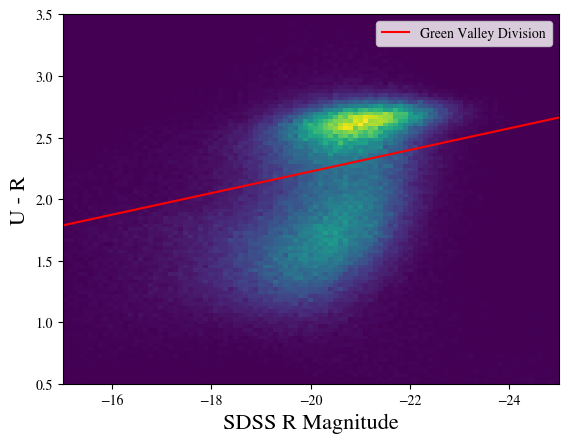

In [8]:
fig, ax = plt.subplots()
plt.hist2d(tabbgs['ABSMAG01_SDSS_R_2'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_R_2'],
           bins=[np.linspace(-25,-15,num=100),np.linspace(0.5,3.5,num=100)])
ax.invert_xaxis()
plt.xlabel("SDSS R Magnitude")
plt.ylabel("U - R")

def pointslopeline(xs,pt,slope):
    ys = (xs - pt[0])*slope + pt[1]
    return ys

xs = np.linspace(-25,-15,num=100)
pt = [-18,2.05]
slope = -(0.35/4)
ys = pointslopeline(xs,pt,slope)
plt.plot(xs,ys,color='red',label = "Green Valley Division")
plt.legend()

'\nxs = np.linspace(-25,-15,num=100)\npt = [-18,2.05]\nslope = -(0.35/4)\nys = pointslopeline(xs,pt,slope)\nplt.plot(xs,ys,color=\'red\',label = "Green Valley Division")\nplt.legend()'

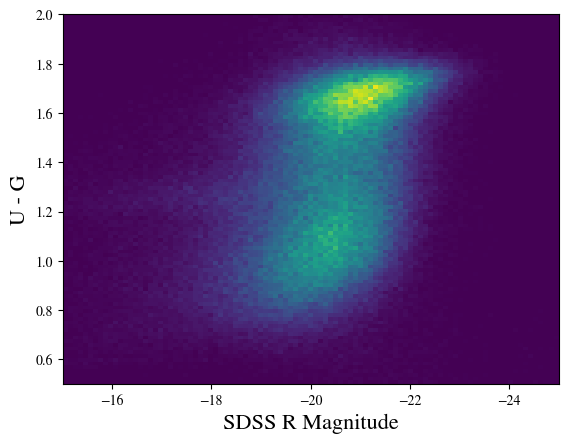

In [9]:
fig, ax = plt.subplots()
plt.hist2d(tabbgs['ABSMAG01_SDSS_R_2'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_G_2'],
           bins=[np.linspace(-25,-15,num=100),np.linspace(0.5,2,num=100)])
ax.invert_xaxis()
plt.xlabel("SDSS R Magnitude")
plt.ylabel("U - G")

def pointslopeline(xs,pt,slope):
    ys = (xs - pt[0])*slope + pt[1]
    return ys
'''
xs = np.linspace(-25,-15,num=100)
pt = [-18,2.05]
slope = -(0.35/4)
ys = pointslopeline(xs,pt,slope)
plt.plot(xs,ys,color='red',label = "Green Valley Division")
plt.legend()'''

'\nxs = np.linspace(-25,-15,num=100)\npt = [-18,2.05]\nslope = -(0.35/4)\nys = pointslopeline(xs,pt,slope)\nplt.plot(xs,ys,color=\'red\',label = "Green Valley Division")\nplt.legend()'

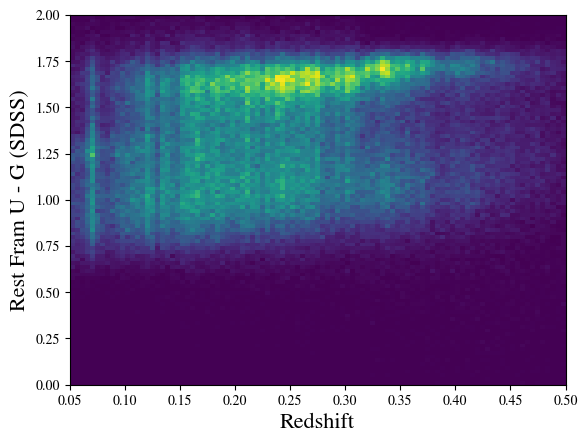

In [10]:
fig, ax = plt.subplots()
plt.hist2d(tabbgs['Z'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_G_2'],
           bins=[np.linspace(0.05,0.5,num=100),np.linspace(0,2,num=100)])
#ax.invert_xaxis()
plt.xlabel("Redshift")
plt.ylabel("Rest Fram U - G (SDSS)")

def pointslopeline(xs,pt,slope):
    ys = (xs - pt[0])*slope + pt[1]
    return ys

'''
xs = np.linspace(-25,-15,num=100)
pt = [-18,2.05]
slope = -(0.35/4)
ys = pointslopeline(xs,pt,slope)
plt.plot(xs,ys,color='red',label = "Green Valley Division")
plt.legend()'''

Text(0, 0.5, 'Rest Fram U - R (SDSS)')

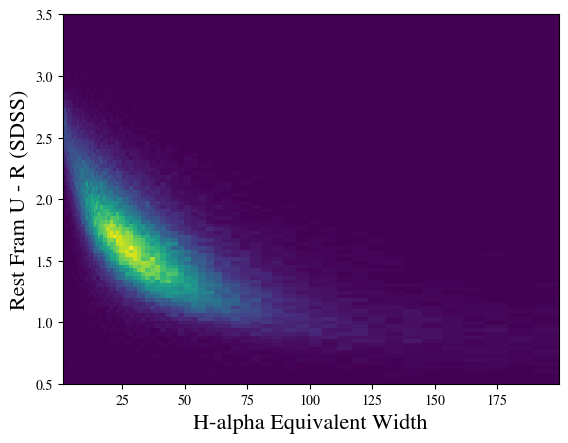

In [12]:
fig, ax = plt.subplots()
'''plt.scatter(tabbgs['HALPHA_EW'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_R_2'],
           s=0.01)'''
plt.hist2d(tabbgs['HALPHA_EW'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_R_2'],
           bins = [np.logspace(0,2.3,num=100),np.linspace(0.5,3.5,num=100)])
#ax.invert_xaxis()
plt.xlabel("H-alpha Equivalent Width")
plt.ylabel("Rest Fram U - R (SDSS)")

Text(0, 0.5, 'Rest Frame U - G (SDSS)')

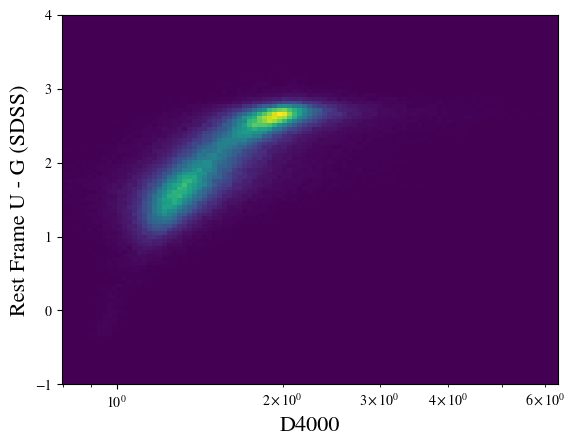

In [13]:
fig, ax = plt.subplots()
plt.hist2d(tabbgs['DN4000_2'],tabbgs['ABSMAG01_SDSS_U_2']-tabbgs['ABSMAG01_SDSS_R_2'],
           bins=[np.logspace(-0.1,0.8,num=100),np.linspace(-1,4,num=100)])
plt.xscale('log')
#ax.invert_xaxis()
plt.xlabel("D4000")
plt.ylabel("Rest Frame U - G (SDSS)")

Text(0, 0.5, 'H-alpha EW')

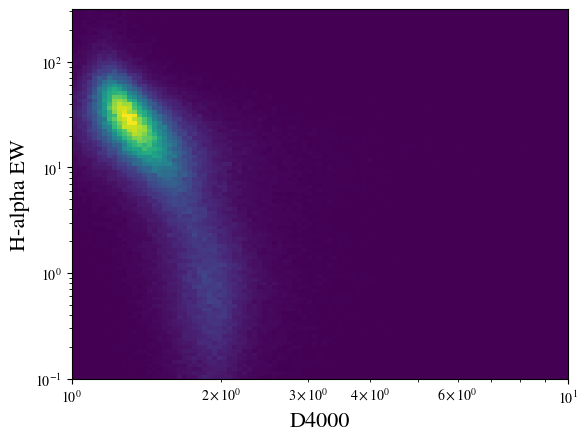

In [14]:
fig, ax = plt.subplots()
plt.hist2d(tabbgs['DN4000_2'],tabbgs['HALPHA_EW'],
           bins=[np.logspace(0,1,num=100),np.logspace(-1,2.5,num=100)])
#plt.xlim(0.1,100)
plt.xscale('log')
#plt.ylim(0.1,500)
plt.yscale('log')
#ax.invert_xaxis()
plt.xlabel("D4000")
plt.ylabel("H-alpha EW")

## Make clustering measurements ##

In [6]:
import importlib
import tools
importlib.reload(tools)

<module 'tools' from '/global/u1/c/crmiller/bgsmaps/tools.py'>

In [7]:
#split into quantiles by luminosity
#test our RA-DEC slicing algorithm
#jackknife regions share RA/DEC boundaries (set by bgs_21_35) across all catalogs
quiltmasks_bgs2135, quiltmasks_bgs, quiltmasks_ran = tools.quiltMasksFromReference(bgs_21_35, [bgs_21_35, tabbgs, bgsrantab], 7, 7)

R_masks = makeNDivMasks(tabbgs, "LOGMSTAR", 100)
D1tab = bgs_21_35
D2tab = tabbgs
D1masks_jack = quiltmasks_bgs2135
D2masks_jack = quiltmasks_bgs
D2masks_samples = R_masks
stringnames = []
for i in range(100):
    stringnames.append("logMstar_quant"+str(i))

In [10]:
edges = [np.arange(1,15,step=1),[-40,40]]
D2counts = tools.subsampleCounts(D1tab, D2tab, D1masks_jack, D2masks_jack, D2masks_samples, stringnames,edges=edges)

In [11]:
stringname = "BGS-21.35xran"
reftab = bgs_21_35
sampletab = bgsrantab
samplemasks_jack = quiltmasks_ran
refmasks_jack = quiltmasks_bgs2135
rancounts = tools.getJackknifeCounts(reftab, sampletab, refmasks_jack, samplemasks_jack, stringname,edges = edges)

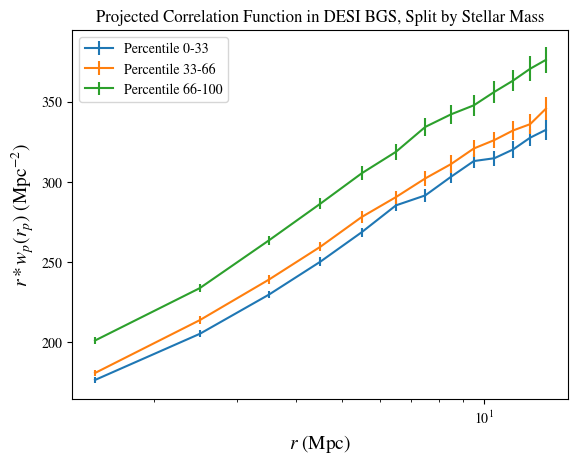

In [14]:
ranges = [[0,33],[33,66],[66,100]]
names = ['Percentile 0-33','Percentile 33-66','Percentile 66-100']
for j in range(len(ranges)):
    D1D2names = []
    for i in np.arange(ranges[j][0],ranges[j][1]):
        D1D2names.append("BGSxquantile_logMstar_quant"+str(i))
    D1R1name = "BGSxquantile_BGS-21.35xran"
    rcenters, DavisPeeblesEstimators, jackerror = tools.DavisPeebles2PCFJackknifeCoadd(D1D2names,D1R1name)
    plt.errorbar(rcenters,DavisPeeblesEstimators,label=names[j],yerr = jackerror)

plt.xscale('log')#, yerr = jackerror)
plt.ylabel(r"$r*w_p(r_p)$ (Mpc$^{-2}$)")
plt.xlabel("$r$ (Mpc)")
plt.title("Projected Correlation Function in DESI BGS, Split by Stellar Mass")
plt.legend()

Text(0.5, 0, '$r$ (Mpc)')

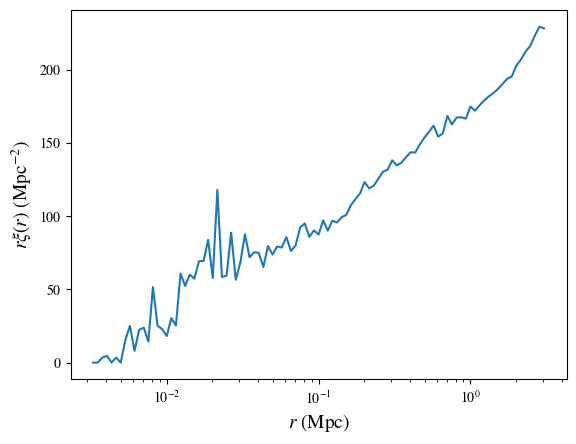